In [1]:
from itertools import chain
from collections import defaultdict
import torch
from torch.utils.data import Subset
from torchvision import datasets
from torchvision import transforms
from transformers import AutoImageProcessor
from transformers import ViTForImageClassification, TrainingArguments, Trainer

c:\Users\KDS-30\Desktop\class\12_VT\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\KDS-30\Desktop\class\12_VT\.venv\lib\site-packages\transformers\utils\generic.py:311: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(
W1001 15:50:40.900000 7784 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
c:\Users\KDS-30\Desktop\class\12_VT\.venv\lib\site-packages\transformers\utils\generic.py:311: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(


In [2]:
def subset_sampler(dataset, classes, max_len):
	target_idx = defaultdict(list)
	for idx, label in enumerate(dataset.train_labels):
		target_idx[int(label)].append(idx)

	indices = list(chain.from_iterable([target_idx[idx][:max_len] for idx in range(len(classes))]))
	return Subset(dataset, indices)

train_dataset = datasets.FashionMNIST(root='../datasets', download = True, train = True)
test_dataset = datasets.FashionMNIST(root='../datasets', download = True, train = False)


100%|██████████| 26.4M/26.4M [00:04<00:00, 5.44MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 109kB/s]
100%|██████████| 4.42M/4.42M [00:02<00:00, 1.85MB/s]
100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]


In [8]:
classes = train_dataset.classes
class_to_idx = train_dataset.class_to_idx

print(classes)
print(class_to_idx)

subset_train_dataset = subset_sampler(dataset = train_dataset, classes = train_dataset.classes, max_len = 1000)
subset_test_dataset = subset_sampler(dataset = test_dataset, classes = test_dataset.classes, max_len = 100)


['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
{'T-shirt/top': 0, 'Trouser': 1, 'Pullover': 2, 'Dress': 3, 'Coat': 4, 'Sandal': 5, 'Shirt': 6, 'Sneaker': 7, 'Bag': 8, 'Ankle boot': 9}


In [9]:
image_processor = AutoImageProcessor.from_pretrained(pretrained_model_name_or_path="google/vit-base-patch16-224-in21k")

transform = transforms.Compose(
	[
		transforms.ToTensor(),
        transforms.Resize(size = (image_processor.size['height'], image_processor.size['width'])),
        transforms.Lambda(lambda x: torch.cat([x, x, x], 0)),
        transforms.Normalize(mean = image_processor.image_mean, std = image_processor.image_std)
	]
)

print(image_processor.size)
print(image_processor.image_mean)
print(image_processor.image_std)

{'height': 224, 'width': 224}
[0.5, 0.5, 0.5]
[0.5, 0.5, 0.5]


In [10]:
from torch.utils.data import DataLoader

def collator(data, transform):
    images, labels = zip(*data)
    pixel_values = torch.stack([transform(image) for image in images])
    labels = torch.tensor([label for label in labels])
    return {'pixel_values' : pixel_values, 'labels' : labels}

train_dataloader = DataLoader(subset_train_dataset, batch_size = 32, shuffle = True, collate_fn = lambda x: collator(x, transform), drop_last = True)
valid_dataloader = DataLoader(subset_test_dataset, batch_size = 4, shuffle = False, collate_fn = lambda x: collator(x, transform), drop_last = True)

batch = next(iter(train_dataloader))
for key, value in batch.items():
    print(key, value.shape)


pixel_values torch.Size([32, 3, 224, 224])
labels torch.Size([32])


In [13]:
model = ViTForImageClassification.from_pretrained(pretrained_model_name_or_path="google/vit-base-patch16-224-in21k",
                                                  num_labels = len(classes), id2label = {idx:label for label, idx in class_to_idx.items()},
                                                  label2id = class_to_idx, ignore_mismatched_sizes = True)

print(model.classifier)

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Linear(in_features=768, out_features=10, bias=True)


In [15]:
print(model.vit.embeddings)

batch = next(iter(train_dataloader))
print(batch['pixel_values'].shape)
print(model.vit.embeddings.patch_embeddings(batch['pixel_values']).shape)
print(model.vit.embeddings(batch['pixel_values']).shape)

ViTEmbeddings(
  (patch_embeddings): ViTPatchEmbeddings(
    (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
  )
  (dropout): Dropout(p=0.0, inplace=False)
)
torch.Size([32, 3, 224, 224])
torch.Size([32, 196, 768])
torch.Size([32, 197, 768])


In [16]:
import evaluate
import numpy as np
def compute_metrics(eval_pred):
    metric = evaluate.load('f1')
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis = 1)
    macro_f1 = metric.compute(predictions = predictions, references = labels,
                              average = 'macro')
    return macro_f1

In [19]:
def model_init(classes, class_to_idx):
    return  ViTForImageClassification.from_pretrained(pretrained_model_name_or_path = "google/vit-base-patch16-224-in21k",
                                                  num_labels = len(classes), id2label = {idx:label for label, idx in class_to_idx.items()},
                                                  label2id = class_to_idx, ignore_mismatched_sizes = True)


args = TrainingArguments(
    output_dir = '../model/ViT-FashionMNIST', save_strategy = 'epoch', evaluation_strategy = 'epoch',
    learning_rate = 1e-5, per_device_train_batch_size = 16, per_device_eval_batch_size = 16,
    num_train_epochs = 3, weight_decay = 0.001, load_best_model_at_end = True,
    metric_for_best_model = 'f1', logging_dir = 'logs', logging_steps = 125,
    remove_unused_columns = False, seed = 42)

trainer = Trainer(model_init = lambda x: model_init(classes, class_to_idx),
                  args = args, train_dataset = subset_train_dataset,
                  eval_dataset = subset_test_dataset,
                  data_collator = lambda x: collator(x, transform),
                  compute_metrics = compute_metrics, tokenizer = image_processor)

trainer.train()

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  7%|▋         | 125/1875 [00:49<11:26,  2.55it/s]

{'loss': 1.9301, 'learning_rate': 9.333333333333334e-06, 'epoch': 0.2}


 13%|█▎        | 250/1875 [01:39<10:54,  2.48it/s]

{'loss': 1.2744, 'learning_rate': 8.666666666666668e-06, 'epoch': 0.4}


 20%|██        | 375/1875 [02:29<09:54,  2.52it/s]

...

                                                   
100%|██████████| 1875/1875 [13:27<00:00,  2.44it/s]

{'eval_loss': 0.4326183497905731, 'eval_f1': 0.9195160183912972, 'eval_runtime': 15.1641, 'eval_samples_per_second': 65.945, 'eval_steps_per_second': 4.155, 'epoch': 3.0}


100%|██████████| 1875/1875 [13:28<00:00,  2.32it/s]

{'train_runtime': 808.6841, 'train_samples_per_second': 37.097, 'train_steps_per_second': 2.319, 'train_loss': 0.693423388671875, 'epoch': 3.0}


TrainOutput(global_step=1875, training_loss=0.693423388671875, metrics={'train_runtime': 808.6841, 'train_samples_per_second': 37.097, 'train_steps_per_second': 2.319, 'train_loss': 0.693423388671875, 'epoch': 3.0})

100%|██████████| 63/63 [00:14<00:00,  4.38it/s]


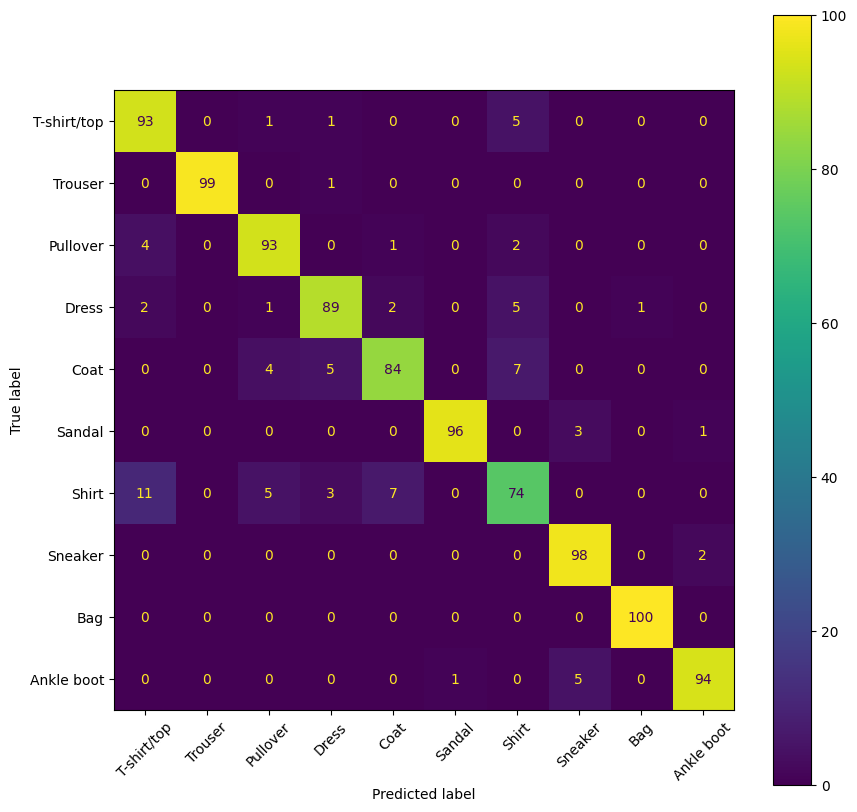

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

outputs = trainer.predict(subset_test_dataset)

y_true = outputs.label_ids
y_pred = outputs.predictions.argmax(1)
labels = list(classes)
matrix = confusion_matrix(y_true, y_pred)
display = ConfusionMatrixDisplay(matrix, display_labels = labels)

_, ax = plt.subplots(figsize = (10, 10))
display.plot(xticks_rotation = 45, ax = ax)
plt.show()